# Customer Satisfaction Analysis
**Project 4 – 3Skill | Data Analytics**

## Objective
Analyze customer survey and feedback data to understand satisfaction levels, ratings, common concerns, issue-resolution performance, and areas for business improvement.

**Dataset:** `Customer_Satisfaction_Analysis_Dataset.xlsx`  
**Important:** This is synthetic data generated for learning and portfolio practice. It does not represent real customers or a real company.


## 1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

## 2. Load Dataset

In [2]:
file_path = "Customer_Satisfaction_Analysis_Dataset.xlsx"

df = pd.read_excel(file_path, sheet_name="Customer_Feedback")
issue_master = pd.read_excel(file_path, sheet_name="Issue_Master")

df.head()

,Response_ID,Customer_ID,Survey_Date,Age_Group,Customer_Segment,Region,Purchase_Channel,Product_Category,Issue_Category,Customer_Rating,Satisfaction_Level,Issue_Resolved,Response_Time_Hours,Resolution_Time_Hours,Feedback_Comment
0,RESP00001,CUST00001,2025-01-29,36-45,New,West,Phone,Clothing,Product Quality,4,Satisfied,Yes,36.50,25.80,The overall experience was smooth and convenient.
1,RESP00002,CUST00002,2025-09-10,36-45,Returning,Central,Email,Clothing,Website/App Experience,3,Neutral,Yes,3.50,7.70,"There were a few delays, but the issue was man..."
2,RESP00003,CUST00003,2025-06-13,36-45,Returning,South,In-Store,Electronics,Pricing,4,Satisfied,Yes,17.80,8.90,The delivery arrived on time and the service w...
3,RESP00004,CUST00004,2025-11-06,36-45,Loyal,North,In-Store,Home & Kitchen,Pricing,5,Satisfied,Yes,32.80,2.30,The team was helpful and resolved my query qui...
4,RESP00005,CUST00005,2025-01-25,26-35,New,West,Mobile App,Beauty,Pricing,2,Dissatisfied,No,48.50,0.00,The return or refund process was frustrating.


## 3. Initial Data Understanding

In [3]:
print("Dataset Shape:", df.shape)
print("\\nDataset Information:")
df.info()

print("\\nMissing Values:")
print(df.isnull().sum())

print("\\nDuplicate Rows:", df.duplicated().sum())
print("Duplicate Response IDs:", df["Response_ID"].duplicated().sum())

print("\\nUnique Values:")
print(df.nunique())

print("\\nDescriptive Statistics:")
display(df.describe(include="all").T)

Dataset Shape: (2500, 15)
\nDataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   Response_ID            2500 non-null   object        
 1   Customer_ID            2500 non-null   object        
 2   Survey_Date            2500 non-null   datetime64[ns]
 3   Age_Group              2500 non-null   object        
 4   Customer_Segment       2500 non-null   object        
 5   Region                 2500 non-null   object        
 6   Purchase_Channel       2500 non-null   object        
 7   Product_Category       2500 non-null   object        
 8   Issue_Category         2500 non-null   object        
 9   Customer_Rating        2500 non-null   int64         
 10  Satisfaction_Level     2500 non-null   object        
 11  Issue_Resolved         2500 non-null   object        
 12  Response_Time

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
Response_ID,2500,2500,RESP00001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer_ID,2500,2500,CUST00001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Survey_Date,2500,NaN,NaN,NaN,2025-06-30 11:54:14.400000,2025-01-01 00:00:00,2025-04-04 00:00:00,2025-06-30 00:00:00,2025-09-27 00:00:00,2025-12-31 00:00:00,NaN
Age_Group,2500,5,26-35,751,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer_Segment,2500,3,Returning,1140,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Region,2500,5,West,655,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Purchase_Channel,2500,5,Mobile App,707,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product_Category,2500,5,Electronics,623,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Issue_Category,2500,6,Delivery,554,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer_Rating,"2,500.00",NaN,NaN,NaN,3.74,1.00,3.00,4.00,4.00,5.00,0.86


## 4. Data Cleaning and Validation

In [4]:
# Work on a copy so the original loaded data remains unchanged
df_clean = df.copy()

# Convert date column to datetime
df_clean["Survey_Date"] = pd.to_datetime(df_clean["Survey_Date"], errors="coerce")

# Remove duplicate response records, if any
df_clean = df_clean.drop_duplicates(subset="Response_ID")

# Standardize text columns
text_columns = [
    "Age_Group", "Customer_Segment", "Region", "Purchase_Channel",
    "Product_Category", "Issue_Category", "Satisfaction_Level",
    "Issue_Resolved", "Feedback_Comment"
]

for col in text_columns:
    df_clean[col] = df_clean[col].astype("string").str.strip()

# Ensure numeric columns are numeric
numeric_columns = [
    "Customer_Rating", "Response_Time_Hours", "Resolution_Time_Hours"
]
for col in numeric_columns:
    df_clean[col] = pd.to_numeric(df_clean[col], errors="coerce")

# Validate rating range
df_clean = df_clean[
    df_clean["Customer_Rating"].between(1, 5)
].copy()

# Create analysis-friendly date fields
df_clean["Month"] = df_clean["Survey_Date"].dt.to_period("M").astype(str)
df_clean["Month_Name"] = df_clean["Survey_Date"].dt.strftime("%b")
df_clean["Quarter"] = df_clean["Survey_Date"].dt.to_period("Q").astype(str)

print("Cleaned Dataset Shape:", df_clean.shape)
print("Missing Values After Cleaning:")
print(df_clean.isnull().sum())
print("Duplicate Response IDs:", df_clean["Response_ID"].duplicated().sum())

Cleaned Dataset Shape: (2500, 18)
Missing Values After Cleaning:
Response_ID              0
Customer_ID              0
Survey_Date              0
Age_Group                0
Customer_Segment         0
Region                   0
Purchase_Channel         0
Product_Category         0
Issue_Category           0
Customer_Rating          0
Satisfaction_Level       0
Issue_Resolved           0
Response_Time_Hours      0
Resolution_Time_Hours    0
Feedback_Comment         0
Month                    0
Month_Name               0
Quarter                  0
dtype: int64
Duplicate Response IDs: 0


## 5. Overall Customer Satisfaction KPIs

In [5]:
total_responses = len(df_clean)
average_rating = df_clean["Customer_Rating"].mean()
satisfied_count = (df_clean["Satisfaction_Level"] == "Satisfied").sum()
neutral_count = (df_clean["Satisfaction_Level"] == "Neutral").sum()
dissatisfied_count = (df_clean["Satisfaction_Level"] == "Dissatisfied").sum()

satisfaction_rate = satisfied_count / total_responses * 100
dissatisfaction_rate = dissatisfied_count / total_responses * 100
issue_resolution_rate = (df_clean["Issue_Resolved"] == "Yes").mean() * 100
average_response_time = df_clean["Response_Time_Hours"].mean()

kpi_summary = pd.DataFrame({
    "Metric": [
        "Total Survey Responses", "Average Customer Rating",
        "Satisfied Customers", "Neutral Customers", "Dissatisfied Customers",
        "Satisfaction Rate (%)", "Dissatisfaction Rate (%)",
        "Issue Resolution Rate (%)", "Average Response Time (Hours)"
    ],
    "Value": [
        total_responses, round(average_rating, 2), satisfied_count,
        neutral_count, dissatisfied_count, round(satisfaction_rate, 2),
        round(dissatisfaction_rate, 2), round(issue_resolution_rate, 2),
        round(average_response_time, 2)
    ]
})

display(kpi_summary)

,Metric,Value
0,Total Survey Responses,"2,500.00"
1,Average Customer Rating,3.74
2,Satisfied Customers,"1,579.00"
3,Neutral Customers,733.00
4,Dissatisfied Customers,188.00
5,Satisfaction Rate (%),63.16
6,Dissatisfaction Rate (%),7.52
7,Issue Resolution Rate (%),82.60
8,Average Response Time (Hours),16.35


## 6. Customer Rating Analysis

,Rating,Customer_Count
0,1,11
1,2,177
2,3,733
3,4,1116
4,5,463


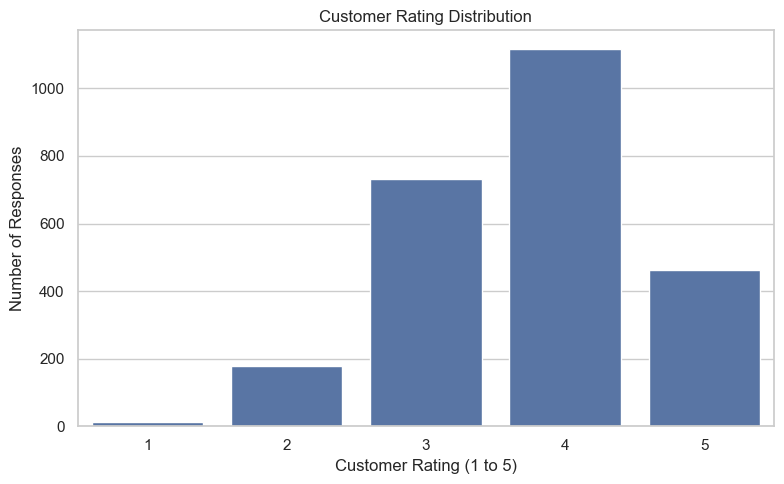

In [6]:
rating_counts = (
    df_clean["Customer_Rating"]
    .value_counts()
    .sort_index()
    .rename_axis("Rating")
    .reset_index(name="Customer_Count")
)

display(rating_counts)

plt.figure(figsize=(8, 5))
sns.barplot(data=rating_counts, x="Rating", y="Customer_Count")
plt.title("Customer Rating Distribution")
plt.xlabel("Customer Rating (1 to 5)")
plt.ylabel("Number of Responses")
plt.tight_layout()
plt.show()

## 7. Satisfaction Level Analysis

,Satisfaction_Level,Customer_Count
0,Satisfied,1579
1,Neutral,733
2,Dissatisfied,188


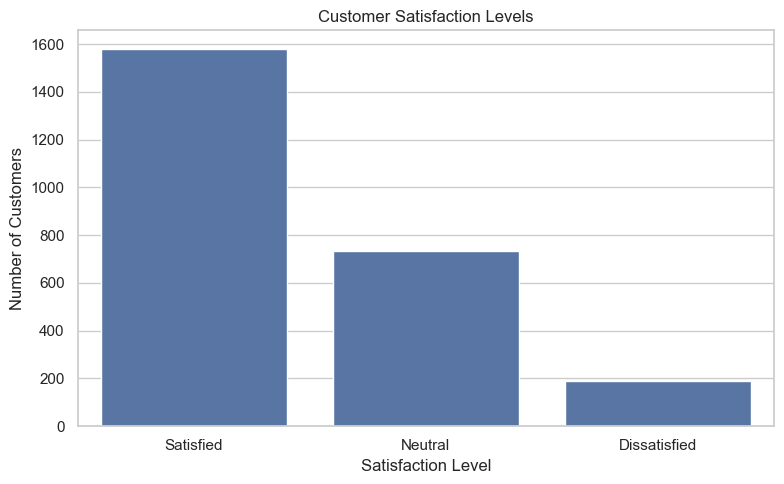

In [7]:
satisfaction_counts = (
    df_clean["Satisfaction_Level"]
    .value_counts()
    .reindex(["Satisfied", "Neutral", "Dissatisfied"])
    .fillna(0)
    .reset_index()
)
satisfaction_counts.columns = ["Satisfaction_Level", "Customer_Count"]

display(satisfaction_counts)

plt.figure(figsize=(8, 5))
sns.barplot(
    data=satisfaction_counts,
    x="Satisfaction_Level",
    y="Customer_Count"
)
plt.title("Customer Satisfaction Levels")
plt.xlabel("Satisfaction Level")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

## 8. Issue / Complaint Category Analysis

,Issue_Category,Total_Responses,Average_Rating,Dissatisfied_Count,Resolution_Rate,Response_Share_Percent
1,Delivery,554,3.77,38,81.23,22.16
3,Product Quality,461,3.71,38,85.25,18.44
0,Customer Support,444,3.76,34,81.53,17.76
5,Website/App Experience,410,3.72,38,85.85,16.40
2,Pricing,332,3.71,21,79.22,13.28
4,Returns & Refunds,299,3.74,19,81.94,11.96


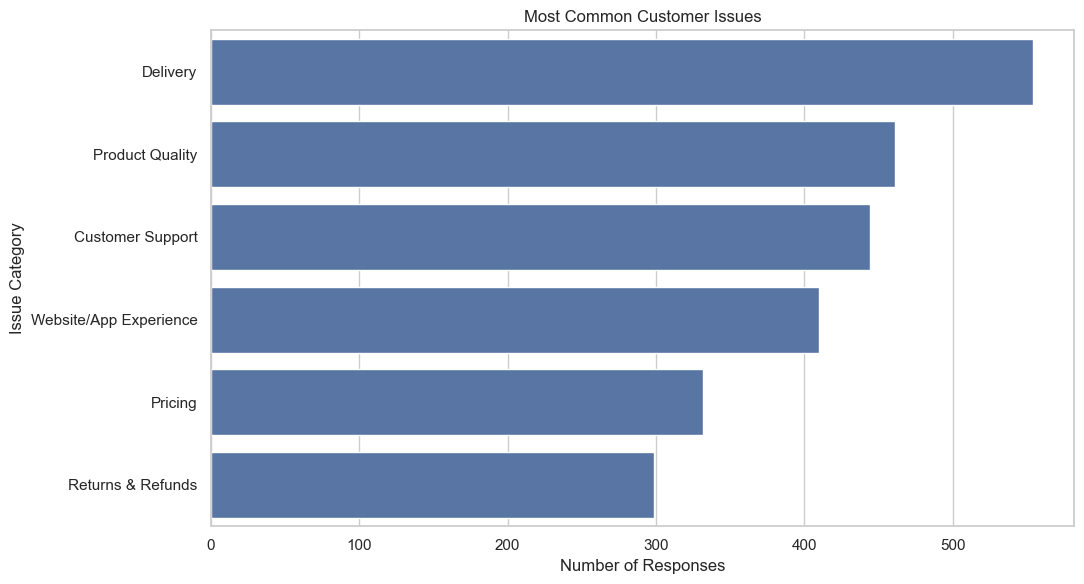

In [8]:
issue_analysis = (
    df_clean.groupby("Issue_Category")
    .agg(
        Total_Responses=("Response_ID", "count"),
        Average_Rating=("Customer_Rating", "mean"),
        Dissatisfied_Count=("Satisfaction_Level", lambda x: (x == "Dissatisfied").sum()),
        Resolution_Rate=("Issue_Resolved", lambda x: (x == "Yes").mean() * 100)
    )
    .reset_index()
)

issue_analysis["Response_Share_Percent"] = (
    issue_analysis["Total_Responses"] / total_responses * 100
)
issue_analysis = issue_analysis.sort_values(
    "Total_Responses", ascending=False
)

display(issue_analysis.round(2))

plt.figure(figsize=(11, 6))
sns.barplot(
    data=issue_analysis,
    y="Issue_Category",
    x="Total_Responses"
)
plt.title("Most Common Customer Issues")
plt.xlabel("Number of Responses")
plt.ylabel("Issue Category")
plt.tight_layout()
plt.show()

## 9. Product Category Analysis

,Product_Category,Total_Responses,Average_Rating,Satisfaction_Rate
2,Electronics,623,3.76,63.72
1,Clothing,520,3.75,61.92
4,Home & Kitchen,535,3.74,63.74
3,Grocery,481,3.73,64.03
0,Beauty,341,3.69,61.88


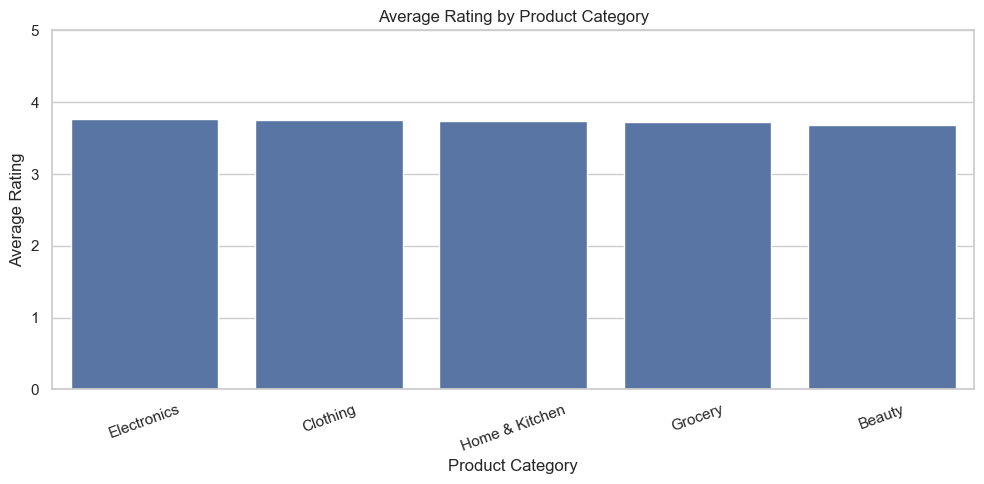

In [9]:
product_analysis = (
    df_clean.groupby("Product_Category")
    .agg(
        Total_Responses=("Response_ID", "count"),
        Average_Rating=("Customer_Rating", "mean"),
        Satisfaction_Rate=("Satisfaction_Level", lambda x: (x == "Satisfied").mean() * 100)
    )
    .reset_index()
    .sort_values("Average_Rating", ascending=False)
)

display(product_analysis.round(2))

plt.figure(figsize=(10, 5))
sns.barplot(
    data=product_analysis,
    x="Product_Category",
    y="Average_Rating"
)
plt.title("Average Rating by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Average Rating")
plt.ylim(0, 5)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## 10. Region-wise Customer Satisfaction

,Region,Total_Responses,Average_Rating,Satisfaction_Rate
0,Central,408,3.80,65.93
2,North,481,3.74,64.03
3,South,556,3.74,63.85
4,West,655,3.72,61.68
1,East,400,3.69,60.75


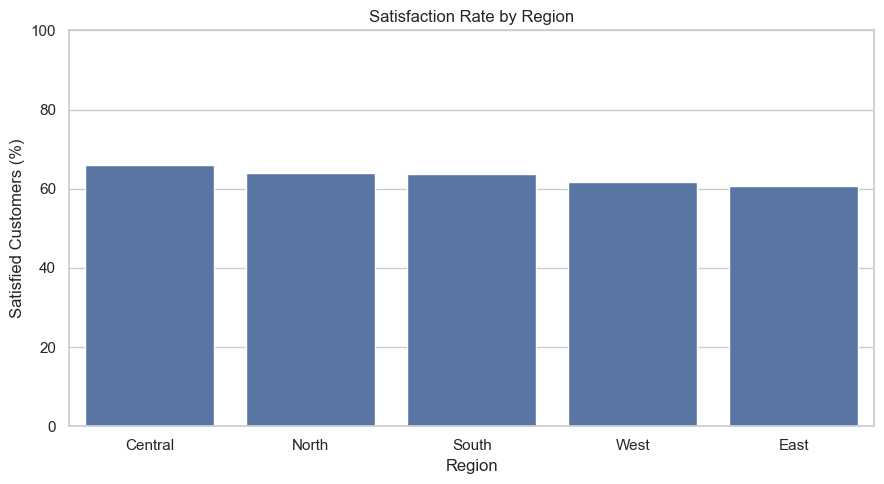

In [10]:
region_analysis = (
    df_clean.groupby("Region")
    .agg(
        Total_Responses=("Response_ID", "count"),
        Average_Rating=("Customer_Rating", "mean"),
        Satisfaction_Rate=("Satisfaction_Level", lambda x: (x == "Satisfied").mean() * 100)
    )
    .reset_index()
    .sort_values("Satisfaction_Rate", ascending=False)
)

display(region_analysis.round(2))

plt.figure(figsize=(9, 5))
sns.barplot(data=region_analysis, x="Region", y="Satisfaction_Rate")
plt.title("Satisfaction Rate by Region")
plt.xlabel("Region")
plt.ylabel("Satisfied Customers (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

## 11. Purchase Channel Analysis

,Purchase_Channel,Total_Responses,Average_Rating,Satisfaction_Rate
4,Website,502,3.79,67.13
1,In-Store,464,3.77,62.93
0,Email,398,3.74,62.56
3,Phone,429,3.72,62.47
2,Mobile App,707,3.69,61.24


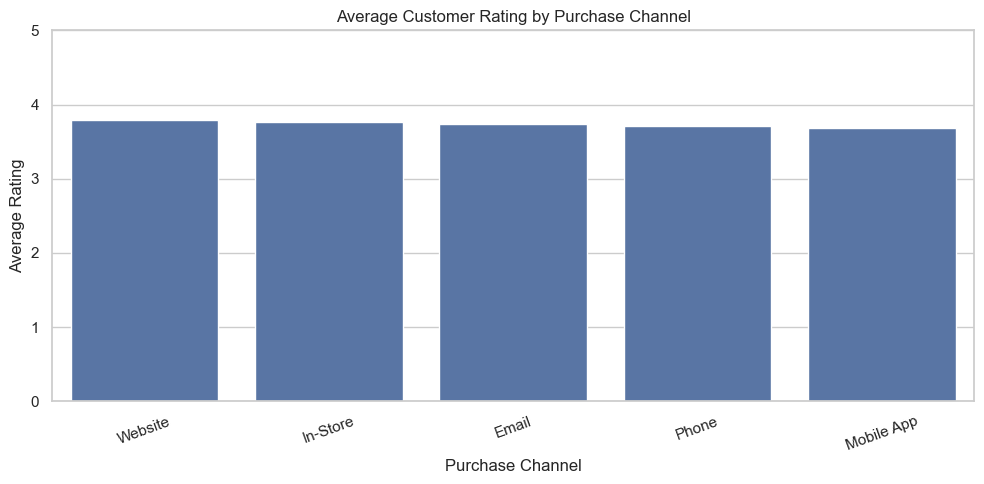

In [11]:
channel_analysis = (
    df_clean.groupby("Purchase_Channel")
    .agg(
        Total_Responses=("Response_ID", "count"),
        Average_Rating=("Customer_Rating", "mean"),
        Satisfaction_Rate=("Satisfaction_Level", lambda x: (x == "Satisfied").mean() * 100)
    )
    .reset_index()
    .sort_values("Average_Rating", ascending=False)
)

display(channel_analysis.round(2))

plt.figure(figsize=(10, 5))
sns.barplot(
    data=channel_analysis,
    x="Purchase_Channel",
    y="Average_Rating"
)
plt.title("Average Customer Rating by Purchase Channel")
plt.xlabel("Purchase Channel")
plt.ylabel("Average Rating")
plt.ylim(0, 5)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## 12. Issue Resolution Analysis

,Issue_Resolved,Total_Cases,Average_Rating,Average_Response_Time,Average_Resolution_Time
0,No,435,3.19,16.46,0.00
1,Yes,2065,3.85,16.33,19.77


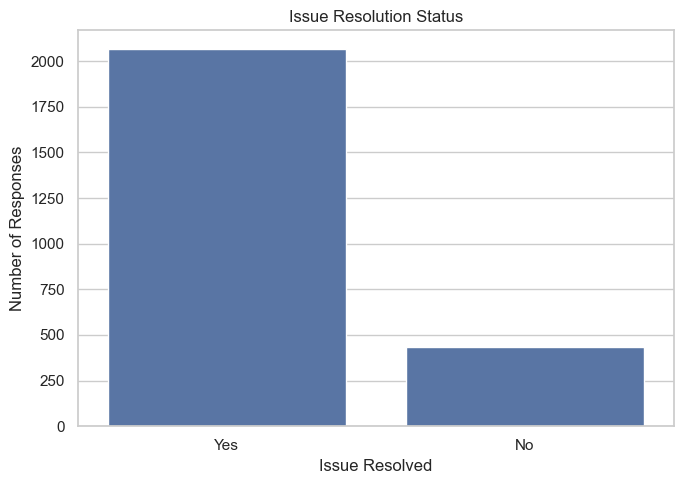

In [12]:
resolution_analysis = (
    df_clean.groupby("Issue_Resolved")
    .agg(
        Total_Cases=("Response_ID", "count"),
        Average_Rating=("Customer_Rating", "mean"),
        Average_Response_Time=("Response_Time_Hours", "mean"),
        Average_Resolution_Time=("Resolution_Time_Hours", "mean")
    )
    .reset_index()
)

display(resolution_analysis.round(2))

plt.figure(figsize=(7, 5))
sns.countplot(data=df_clean, x="Issue_Resolved")
plt.title("Issue Resolution Status")
plt.xlabel("Issue Resolved")
plt.ylabel("Number of Responses")
plt.tight_layout()
plt.show()

## 13. Monthly Satisfaction Trend

,Month,Total_Responses,Average_Rating,Satisfaction_Rate
0,2025-01,217,3.75,62.67
1,2025-02,202,3.73,62.87
2,2025-03,180,3.73,63.33
3,2025-04,220,3.67,59.09
4,2025-05,231,3.81,64.07
5,2025-06,201,3.76,63.68
6,2025-07,218,3.78,66.51
7,2025-08,224,3.79,67.86
8,2025-09,206,3.64,58.74
9,2025-10,190,3.72,62.63


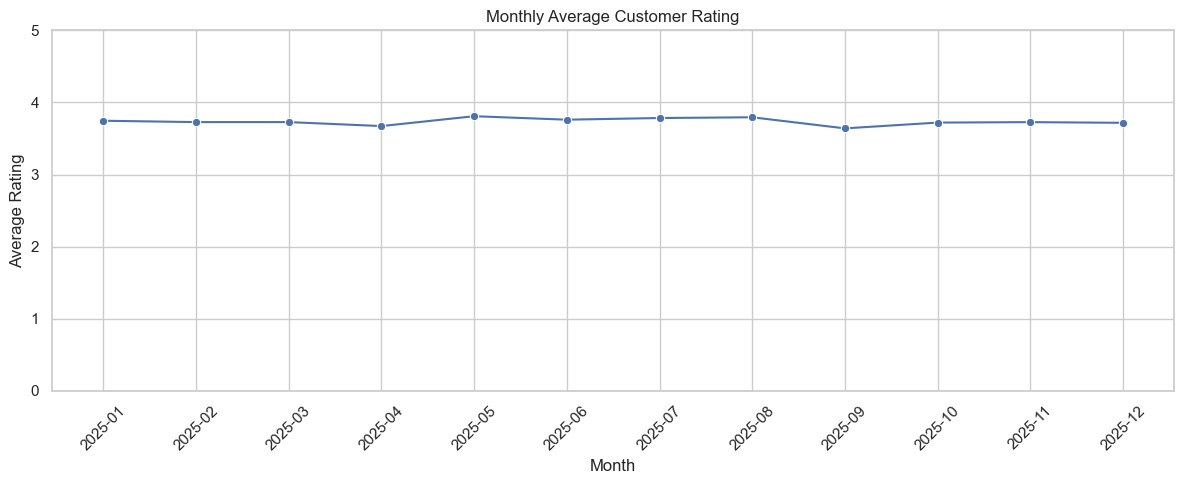

In [13]:
monthly_analysis = (
    df_clean.groupby("Month")
    .agg(
        Total_Responses=("Response_ID", "count"),
        Average_Rating=("Customer_Rating", "mean"),
        Satisfaction_Rate=("Satisfaction_Level", lambda x: (x == "Satisfied").mean() * 100)
    )
    .reset_index()
    .sort_values("Month")
)

display(monthly_analysis.round(2))

plt.figure(figsize=(12, 5))
sns.lineplot(
    data=monthly_analysis,
    x="Month",
    y="Average_Rating",
    marker="o"
)
plt.title("Monthly Average Customer Rating")
plt.xlabel("Month")
plt.ylabel("Average Rating")
plt.xticks(rotation=45)
plt.ylim(0, 5)
plt.tight_layout()
plt.show()

## 14. Customer Segment Analysis

,Customer_Segment,Total_Responses,Average_Rating,Satisfaction_Rate
0,Loyal,638,3.77,64.11
1,New,722,3.72,63.16
2,Returning,1140,3.73,62.63


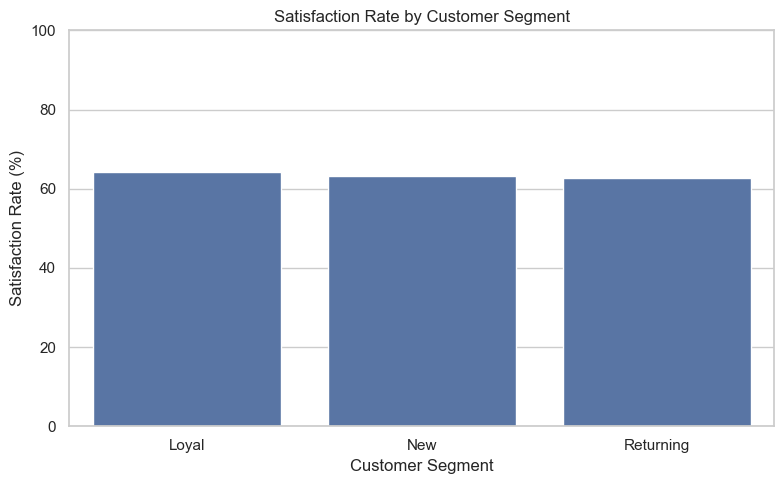

In [14]:
segment_analysis = (
    df_clean.groupby("Customer_Segment")
    .agg(
        Total_Responses=("Response_ID", "count"),
        Average_Rating=("Customer_Rating", "mean"),
        Satisfaction_Rate=("Satisfaction_Level", lambda x: (x == "Satisfied").mean() * 100)
    )
    .reset_index()
)

display(segment_analysis.round(2))

plt.figure(figsize=(8, 5))
sns.barplot(
    data=segment_analysis,
    x="Customer_Segment",
    y="Satisfaction_Rate"
)
plt.title("Satisfaction Rate by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Satisfaction Rate (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

## 15. Feedback Comment Review

In [15]:
# Review representative comments by satisfaction level.
# This is a descriptive review, not an automated sentiment model.

for level in ["Dissatisfied", "Neutral", "Satisfied"]:
    print(f"\\n--- {level} Feedback Examples ---")
    comments = (
        df_clean.loc[
            df_clean["Satisfaction_Level"] == level,
            "Feedback_Comment"
        ]
        .drop_duplicates()
        .head(5)
    )
    for comment in comments:
        print("-", comment)

\n--- Dissatisfied Feedback Examples ---
- The return or refund process was frustrating.
- The product did not meet my expectations.
- The issue took too long to resolve.
- I had difficulty getting support from the team.
- Delivery was delayed and communication was poor.
\n--- Neutral Feedback Examples ---
- There were a few delays, but the issue was manageable.
- The product was fine, although some improvements are needed.
- The experience was acceptable but could be improved.
- The process was okay, but not particularly impressive.
- The service was average and met basic expectations.
\n--- Satisfied Feedback Examples ---
- The overall experience was smooth and convenient.
- The delivery arrived on time and the service was good.
- The team was helpful and resolved my query quickly.
- Easy to use and the experience was satisfactory.
- The product quality met my expectations.


## 16. Automatic Business Insights

In [16]:
top_issue = issue_analysis.iloc[0]
lowest_rating_product = product_analysis.sort_values("Average_Rating").iloc[0]
best_rating_product = product_analysis.sort_values("Average_Rating", ascending=False).iloc[0]
lowest_satisfaction_region = region_analysis.sort_values("Satisfaction_Rate").iloc[0]
lowest_satisfaction_channel = channel_analysis.sort_values("Satisfaction_Rate").iloc[0]

print("========== CUSTOMER SATISFACTION INSIGHTS ==========")
print(f"Total survey responses: {total_responses:,}")
print(f"Average customer rating: {average_rating:.2f} / 5")
print(f"Overall satisfaction rate: {satisfaction_rate:.2f}%")
print(f"Issue resolution rate: {issue_resolution_rate:.2f}%")
print(f"Most reported issue: {top_issue['Issue_Category']} ({int(top_issue['Total_Responses'])} responses)")
print(f"Lowest-rated product category: {lowest_rating_product['Product_Category']} ({lowest_rating_product['Average_Rating']:.2f}/5)")
print(f"Highest-rated product category: {best_rating_product['Product_Category']} ({best_rating_product['Average_Rating']:.2f}/5)")
print(f"Lowest satisfaction region: {lowest_satisfaction_region['Region']} ({lowest_satisfaction_region['Satisfaction_Rate']:.2f}%)")
print(f"Lowest satisfaction channel: {lowest_satisfaction_channel['Purchase_Channel']} ({lowest_satisfaction_channel['Satisfaction_Rate']:.2f}%)")

========== CUSTOMER SATISFACTION INSIGHTS ==========
Total survey responses: 2,500
Average customer rating: 3.74 / 5
Overall satisfaction rate: 63.16%
Issue resolution rate: 82.60%
Most reported issue: Delivery (554 responses)
Lowest-rated product category: Beauty (3.69/5)
Highest-rated product category: Electronics (3.76/5)
Lowest satisfaction region: East (60.75%)
Lowest satisfaction channel: Mobile App (61.24%)


## 17. Business Recommendations

In [17]:
recommendations = [
    "Prioritize the most frequently reported issue category and investigate its root causes.",
    "Review low-rated product categories with product and quality teams.",
    "Improve response and resolution processes for unresolved customer cases.",
    "Compare satisfaction across regions and channels to identify service gaps.",
    "Monitor customer ratings and satisfaction trends monthly.",
    "Review dissatisfied feedback comments and classify recurring themes.",
    "Repeat customer surveys regularly to measure whether improvement actions work."
]

for number, recommendation in enumerate(recommendations, start=1):
    print(f"{number}. {recommendation}")

1. Prioritize the most frequently reported issue category and investigate its root causes.
2. Review low-rated product categories with product and quality teams.
3. Improve response and resolution processes for unresolved customer cases.
4. Compare satisfaction across regions and channels to identify service gaps.
5. Monitor customer ratings and satisfaction trends monthly.
6. Review dissatisfied feedback comments and classify recurring themes.
7. Repeat customer surveys regularly to measure whether improvement actions work.


## 18. Export Analysis Reports

In [18]:
# Export cleaned data and analysis tables
df_clean.to_csv("Customer_Feedback_Cleaned.csv", index=False)
kpi_summary.to_csv("Customer_Satisfaction_KPIs.csv", index=False)
rating_counts.to_csv("Customer_Rating_Analysis.csv", index=False)
satisfaction_counts.to_csv("Satisfaction_Level_Analysis.csv", index=False)
issue_analysis.to_csv("Issue_Category_Analysis.csv", index=False)
product_analysis.to_csv("Product_Category_Analysis.csv", index=False)
region_analysis.to_csv("Region_Analysis.csv", index=False)
channel_analysis.to_csv("Purchase_Channel_Analysis.csv", index=False)
monthly_analysis.to_csv("Monthly_Satisfaction_Trend.csv", index=False)
segment_analysis.to_csv("Customer_Segment_Analysis.csv", index=False)

print("All analysis reports exported successfully!")

All analysis reports exported successfully!


## 19. Project Conclusion

This project analyzes customer survey responses to evaluate customer satisfaction, understand rating patterns, identify common customer concerns, and review issue-resolution performance.

The analysis uses KPIs, category-level comparisons, regional and channel analysis, monthly trends, and feedback-comment review to highlight areas that may require business attention.

Recommendations should be validated with additional customer research and operational data before business decisions are made.

**Dataset disclosure:** The dataset and feedback comments are synthetic and were created for educational and portfolio practice. They must not be presented as real customer research.
